# 📄 Automatic Document & ID Scanner
**Computer Vision · Tier 1 · Project 1**

Turns a phone photo of a page or ID card, taken at an angle, into a flat, clean "scanned" image.

**Pipeline**
1. Canny edges
2. Contour / corner detection → find the 4 page corners
3. Homography → `warpPerspective`
4. Adaptive threshold → clean "scanned" look

Run the cells from top to bottom. Every step plots its result, and the settings you may want to adjust are the capitalised variables at the top of each cell.

## Setup

In [9]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

## Step 1 · Upload your photo
Pick **one** image (a document or an ID, it doesn't matter). Keep the whole page inside the frame and, if you can, shoot it on a darker plain surface.

Saving 15_1.jpg to 15_1 (1).jpg
Loaded 15_1 (1).jpg - 3024 x 4032 px


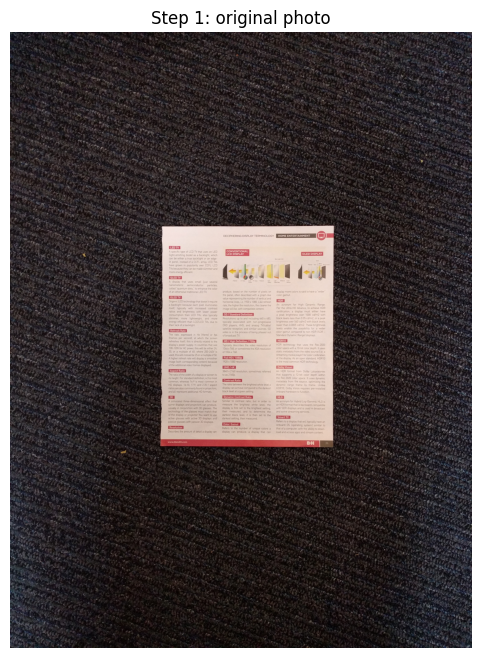

In [10]:
# In Colab this opens a file picker. Outside Colab it reads the path below instead.
try:
    from google.colab import files
    uploaded = files.upload()
    IMAGE_PATH = list(uploaded.keys())[0]
except ImportError:
    IMAGE_PATH = "samples/15_1.jpg"   # <- change this if you run it locally

# OpenCV reads images in BGR order (matplotlib wants RGB, so we convert when plotting)
img = cv2.imread(IMAGE_PATH)
if img is None:
    raise FileNotFoundError(f"Couldn't read '{IMAGE_PATH}'. Is it a valid image file?")
print("Loaded", IMAGE_PATH, "-", img.shape[1], "x", img.shape[0], "px")

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Step 1: original photo")
plt.axis("off")
plt.show()

## Step 2 · Canny edges
Shrink the photo (phone images are huge, so edge detection is faster and cleaner on a smaller copy), blur away the noise, then run Canny. A small close + dilate joins broken edge pieces into one outline.

**If the page outline is broken or missing:** lower `CANNY_LOW` / `CANNY_HIGH`. **If there is too much background clutter:** raise them.

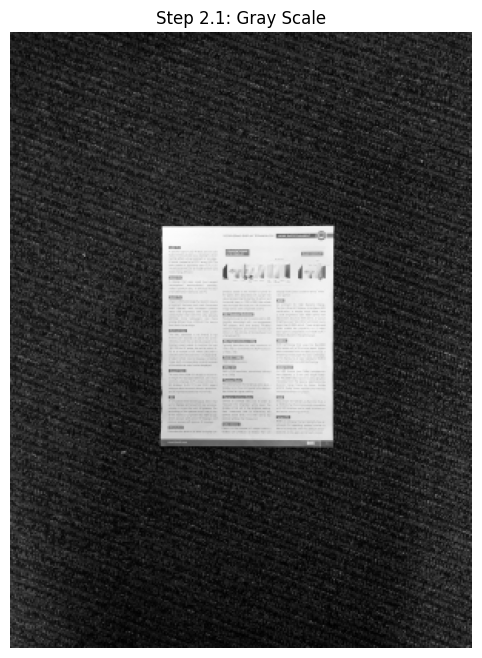

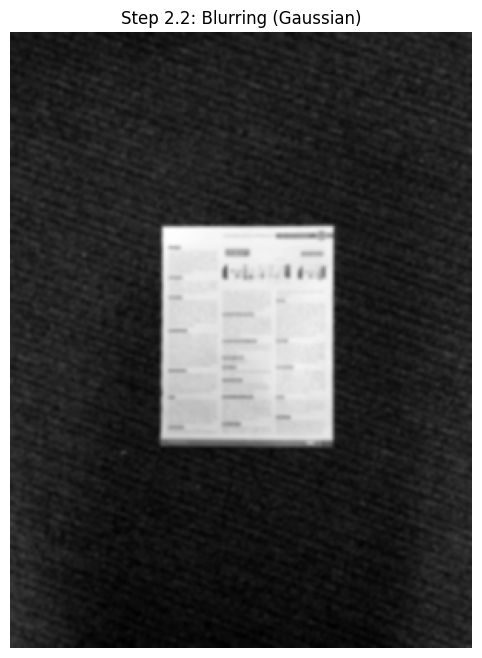

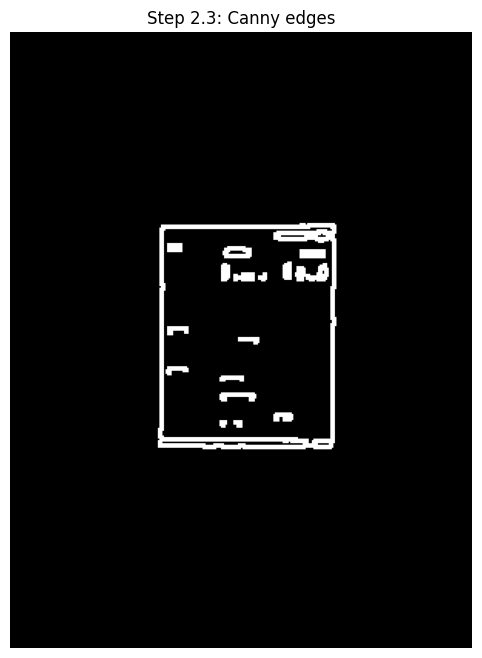

In [11]:
DETECT_HEIGHT = 400   # height (px) of the shrunken copy used for detection
CANNY_LOW = 120        # weak-edge threshold
CANNY_HIGH = 150      # strong-edge threshold

# shrink the photo; `ratio` remembers the scale so we can map the corners back later
h, w = img.shape[:2]
ratio = h / DETECT_HEIGHT
small = cv2.resize(img, (int(w / ratio), DETECT_HEIGHT), interpolation=cv2.INTER_AREA)

# grayscale + blur: Canny reacts to every tiny bump, so we smooth the paper texture first
gray_small = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(8, 8))
plt.imshow(gray_small, cmap="gray")
plt.title("Step 2.1: Gray Scale")
plt.axis("off")
plt.show()

blurred = cv2.GaussianBlur(gray_small, (5, 5), 0)

plt.figure(figsize=(8, 8))
plt.imshow(blurred, cmap="gray")
plt.title("Step 2.2: Blurring (Gaussian)")
plt.axis("off")
plt.show()

# Canny edge detection
edges = cv2.Canny(blurred, CANNY_LOW, CANNY_HIGH)

# close small gaps in the edges, then thicken them a little so the outline is one piece
kernel = np.ones((3, 3), np.uint8)
edges = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel)
edges = cv2.dilate(edges, kernel, iterations=1)

plt.figure(figsize=(8, 8))
plt.imshow(edges, cmap="gray")
plt.title("Step 2.3: Canny edges")
plt.axis("off")
plt.show()

## Step 3 · Contour & corner detection
Find every contour in the edge map, then keep the biggest one that simplifies to a convex shape with exactly 4 corners. That should be the page. The 4 points are then put in a fixed order (top-left → top-right → bottom-right → bottom-left) and scaled back to the full-size photo.

**If the green box is on the wrong object:** raise `MIN_AREA_RATIO` or tweak the Canny thresholds in Step 2. **If you get an error:** the page outline wasn't closed, so go back to Step 2.

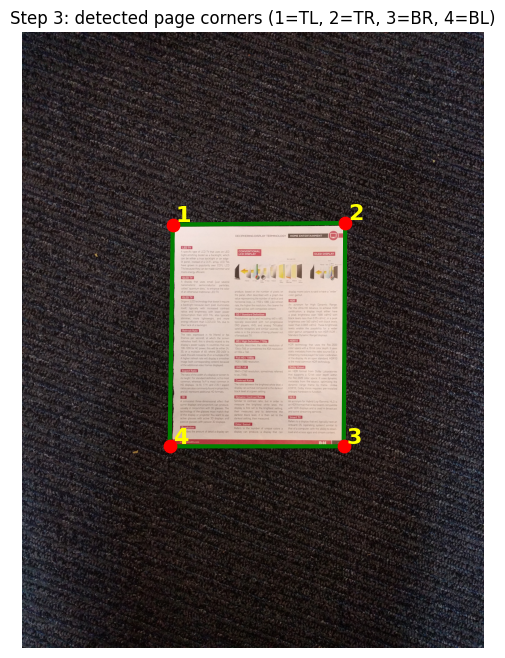

In [12]:
MIN_AREA_RATIO = 0.1   # the page must cover at least 20% of the photo (adjust as needed)
APPROX_EPSILON = 0.02  # how aggressively a contour is simplified to a polygon

# find all contours and look at the 10 biggest ones, largest first
contours, _ = cv2.findContours(edges, cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)
contours = sorted(contours, key=cv2.contourArea, reverse=True)[:10]

# keep the first (biggest) contour that boils down to a convex 4-sided shape
page_contour = None
for c in contours:
    if cv2.contourArea(c) < MIN_AREA_RATIO * small.shape[0] * small.shape[1]:
        break  # contours are sorted by size, so the rest are too small as well
    perimeter = cv2.arcLength(c, True)
    approx = cv2.approxPolyDP(c, APPROX_EPSILON * perimeter, True)
    if len(approx) == 4 and cv2.isContourConvex(approx):
        page_contour = approx
        break

if page_contour is None:
    raise ValueError("No 4-corner page found. Adjust the Canny thresholds in Step 2 "
                     "or MIN_AREA_RATIO here, or use a plainer background.")

# order the corners: top-left has the smallest x+y, bottom-right the largest;
# top-right has the smallest y-x, bottom-left the largest
pts = page_contour.reshape(4, 2).astype("float32")
s = pts.sum(axis=1)
d = np.diff(pts, axis=1).ravel()
corners = np.array([pts[np.argmin(s)],    # 1: top-left
                    pts[np.argmin(d)],    # 2: top-right
                    pts[np.argmax(s)],    # 3: bottom-right
                    pts[np.argmax(d)]],   # 4: bottom-left
                   dtype="float32")

# scale the corners back up to the full-resolution photo
corners = corners * ratio

# plot the detected page on the original photo
plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
outline = np.vstack([corners, corners[:1]])
plt.plot(outline[:, 0], outline[:, 1], "g-", linewidth=3)
plt.scatter(corners[:, 0], corners[:, 1], c="red", s=80, zorder=3)
for i, (x, y) in enumerate(corners):
    plt.text(x + 20, y - 20, str(i + 1), color="yellow", fontsize=16, weight="bold")
plt.title("Step 3: detected page corners (1=TL, 2=TR, 3=BR, 4=BL)")
plt.axis("off")
plt.show()

## Step 4 · Homography + `warpPerspective`
Work out how big the flat page should be, build the homography that maps the 4 corners onto a perfect rectangle, and warp the full-resolution photo with it.

Homography matrix:
 [[ 1.02959356e+00  1.42998913e-02 -1.03509153e+03]
 [ 9.19794920e-03  1.03017488e+00 -1.30710645e+03]
 [ 6.29565276e-06  6.36959748e-06  1.00000000e+00]]
Output size: 1139 x 1462 px


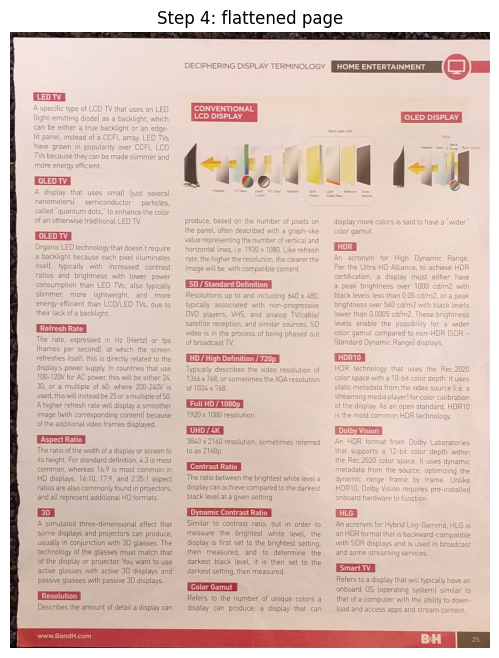

In [13]:
tl, tr, br, bl = corners

# output size: use the longer of each pair of opposite sides
out_w = int(round(max(np.linalg.norm(tr - tl), np.linalg.norm(br - bl))))
out_h = int(round(max(np.linalg.norm(bl - tl), np.linalg.norm(br - tr))))

# where the 4 corners should land: the corners of a flat rectangle
destination = np.array([[0, 0],
                        [out_w - 1, 0],
                        [out_w - 1, out_h - 1],
                        [0, out_h - 1]], dtype="float32")

# homography (3x3 matrix) from the skewed page to the flat rectangle, then warp
H = cv2.getPerspectiveTransform(corners, destination)
warped = cv2.warpPerspective(img, H, (out_w, out_h), flags=cv2.INTER_CUBIC)

print("Homography matrix:\n", H)
print("Output size:", out_w, "x", out_h, "px")

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(warped, cv2.COLOR_BGR2RGB))
plt.title("Step 4: flattened page")
plt.axis("off")
plt.show()

## Step 5 · Adaptive threshold
Each pixel is compared with the average of its own neighbourhood instead of one global value, so shadows and uneven lighting don't ruin the scan.

**Text broken or too thin:** lower `C` (try 5) or raise `BLOCK_SIZE` (try 31). **Speckles in the background:** raise `C` (try 15).

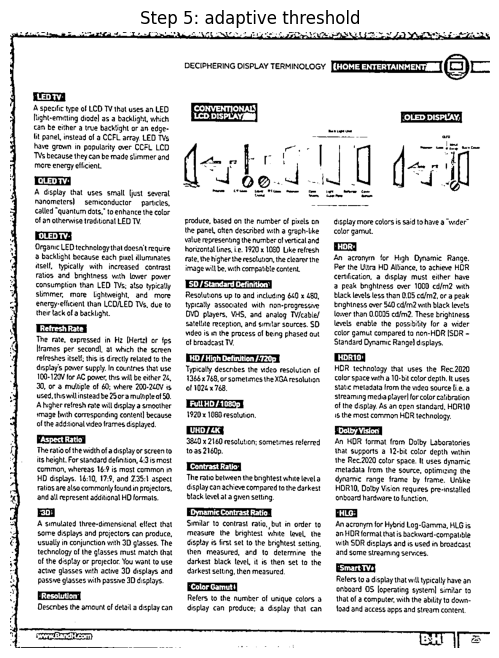

In [14]:
BLOCK_SIZE = 21   # neighbourhood size in pixels (must be odd)
C = 10            # subtracted from the local average: higher = whiter background

# grayscale + a light blur, then threshold every pixel against its local neighbourhood
gray_warped = cv2.cvtColor(warped, cv2.COLOR_BGR2GRAY)
gray_warped = cv2.GaussianBlur(gray_warped, (3, 3), 0)
scanned = cv2.adaptiveThreshold(gray_warped, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                cv2.THRESH_BINARY, BLOCK_SIZE, C)

plt.figure(figsize=(8, 8))
plt.imshow(scanned, cmap="gray")
plt.title("Step 5: adaptive threshold")
plt.axis("off")
plt.show()

## Step 6 · Final scan
Show the finished scan and save it in the repo's `outputs/` folder.

Saved to outputs/15_1 (1)_scan.png
Done - 1139 x 1462 px


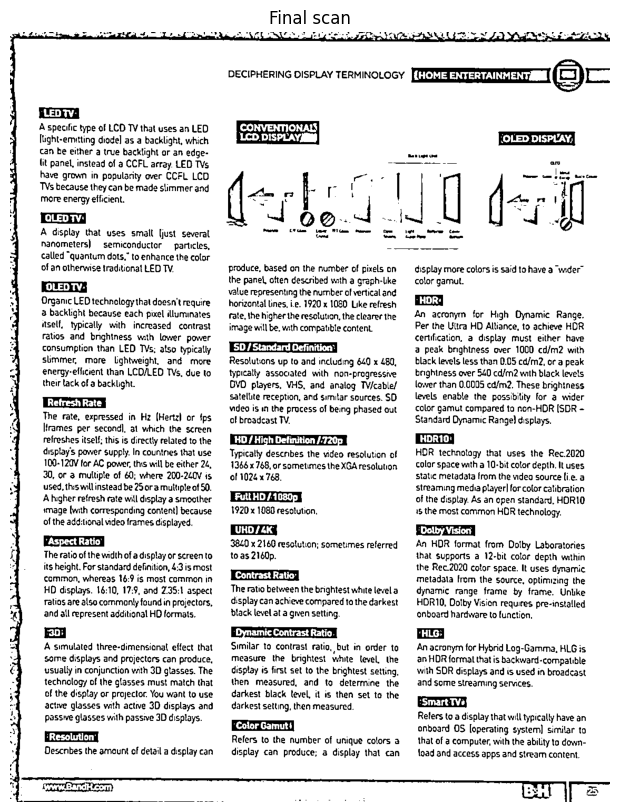

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [15]:
# save next to the notebook, in outputs/
os.makedirs("outputs", exist_ok=True)
stem = os.path.splitext(os.path.basename(IMAGE_PATH))[0]
OUTPUT_PATH = f"outputs/{stem}_scan.png"
cv2.imwrite(OUTPUT_PATH, scanned)
print("Saved to", OUTPUT_PATH)
print("Done", "-", scanned.shape[1], "x", scanned.shape[0], "px")

plt.figure(figsize=(10, 10))
plt.imshow(scanned, cmap="gray")
plt.title("Final scan")
plt.axis("off")
plt.show()

# Colab's storage disappears when the session ends, so also download a copy
try:
    from google.colab import files
    files.download(OUTPUT_PATH)
except ImportError:
    pass